# 06 · Final grafikler (İngilizce, slaytlar için)

Bu notebook 04 ve 05'in kaydettiği tablolardan sunumdaki 3 ana grafiği üretir. **Önce 04 ve 05 çalıştırılmış olmalı.**

| Grafik | Slayt | Tek mesajı |
|---|---|---|
| `final_1_same_path.png` | 2 | Ülkeler aynı yoldan geçiyor, fark zamanlamada |
| `final_2_money_or_school.png` | 3 | Dönüm noktasında gelir dağınık, eğitim daha toplu, ama eğitim de zamanı tek başına söylemiyor |
| `final_3_turkiye.png` | 4 | Türkiye: nüfus zirvesi ve belirsizlik + dönüm noktasındaki konumu |

**Tasarım kuralları (her grafikte):**
- Başlık bir sonuç cümlesi.
- Düz çizgi UN tahmini (≤2023), kesikli çizgi UN projeksiyonu (≥2024).
- Renk körü dostu sabit renkler: Türkiye mavi, Japonya turuncu, Nijerya yeşil, diğerleri gri.
- Tek y ekseni, sade ızgara, kaynak notu altta.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ortak stil
MAVI, TURUNCU, YESIL, GRI = "#2a78d6", "#eb6834", "#1baf7a", "#9e9e9e"
YAZI, YAZI2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": YAZI2, "xtick.color": YAZI2, "ytick.color": YAZI2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "font.size": 11, "axes.titlesize": 12,
})
def baslik(fig, ana, alt):
    fig.text(0.01, 0.985, ana, fontsize=16, fontweight="bold", color=YAZI, va="top")
    fig.text(0.01, 0.925, alt, fontsize=11.5, color=YAZI2, va="top")
def kaynak(fig, metin):
    fig.text(0.01, 0.01, metin, fontsize=8.5, color=YAZI2, va="bottom")

df = pd.read_csv("../clean/countries_1950_2100.csv")
df = df[df["pop2023"] >= 100]
t0 = pd.read_csv("../clean/t0_tablosu.csv").set_index("Location")
po = pd.read_csv("../clean/para_okul_tablosu.csv")
print(df["LocID"].nunique(), "ülke |", len(po), "ülke (para/okul)")

200 ülke | 66 ülke (para/okul)


## Grafik 1: Aynı yol, farklı zaman

04'teki ortak eğri tekrar hesaplanmıyor. Sadece çizim için U, L, k değerleri (04'ün çıktısı) kullanılıyor.

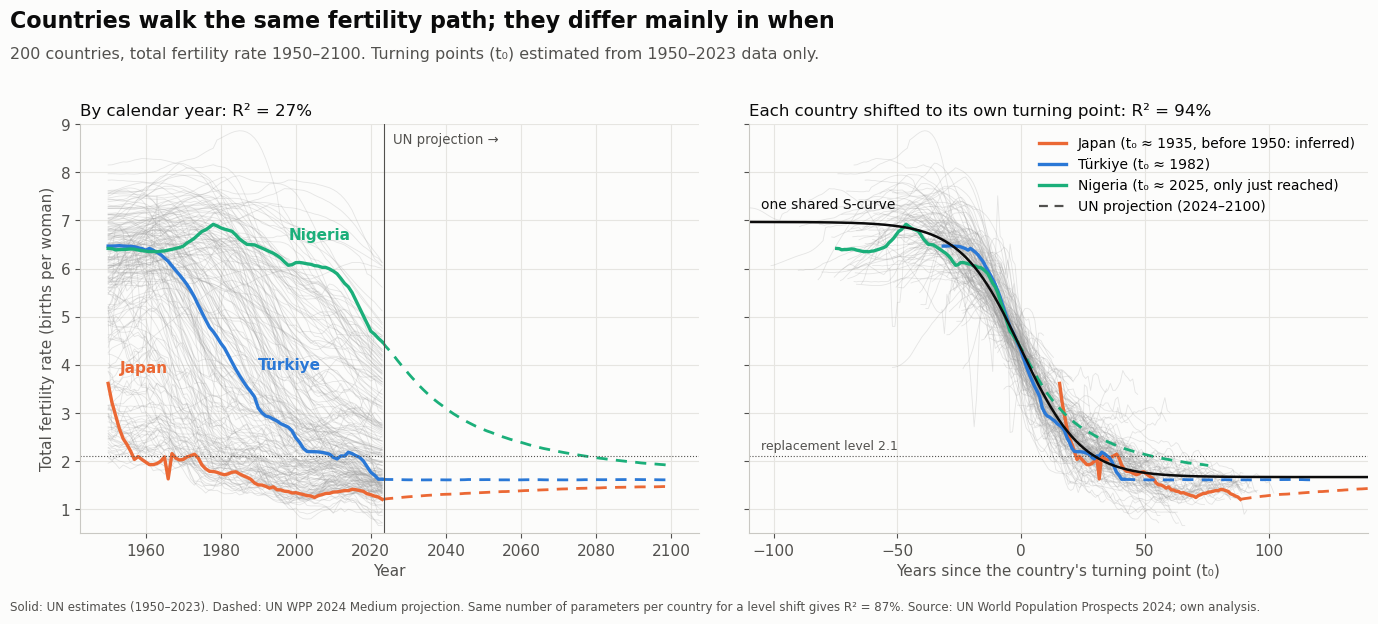

In [10]:
U, L, k = 6.97, 1.67, 0.0816                      # 04 notebook'u, 4. bölüm
def s_egrisi(t, L, U, k, t0): return L + (U - L) / (1 + np.exp(k * (t - t0)))

tum = df.pivot(index="Location", columns="Time", values="TFR")
yil = tum.columns.values
vurgu = {"Japan": TURUNCU, "Türkiye": MAVI, "Nigeria": YESIL}

fig, ax = plt.subplots(1, 2, figsize=(14, 6.2), sharey=True)
fig.subplots_adjust(top=0.80, bottom=0.14, left=0.06, right=0.98, wspace=0.08)
for i, kaydir in enumerate([False, True]):
    a = ax[i]
    for ulke in tum.index:
        if ulke in vurgu: continue
        x = yil - t0.at[ulke, "t0"] if kaydir else yil
        a.plot(x[yil <= 2023], tum.loc[ulke][yil <= 2023], color=GRI, lw=0.6, alpha=0.25)
    for ulke, r in vurgu.items():
        x = yil - t0.at[ulke, "t0"] if kaydir else yil
        a.plot(x[yil <= 2023], tum.loc[ulke][yil <= 2023], color=r, lw=2.4)
        a.plot(x[yil >= 2023], tum.loc[ulke][yil >= 2023], color=r, lw=2, ls=(0, (4, 3)))
    a.axhline(2.1, color=YAZI2, lw=0.8, ls=":")
if True:
    z = np.linspace(-110, 140, 300)
    ax[1].plot(z, s_egrisi(z, L, U, k, 0), color=YAZI, lw=1.8)
    ax[1].text(-105, 7.25, "one shared S-curve", color=YAZI, fontsize=10)
ax[0].axvline(2023.5, color=YAZI2, lw=0.8)
ax[0].text(2026, 8.6, "UN projection →", color=YAZI2, fontsize=9.5)
ax[1].text(-105, 2.25, "replacement level 2.1", color=YAZI2, fontsize=9)
ax[1].set_xlim(-110, 140); ax[0].set_ylim(0.5, 9)
# Doğrudan etiketler (sol panel)
ax[0].text(1953, 1.95 + 1.9, "Japan", color=TURUNCU, fontsize=11, fontweight="bold")
ax[0].text(1990, 3.9, "Türkiye", color=MAVI, fontsize=11, fontweight="bold")
ax[0].text(1998, 6.6, "Nigeria", color=YESIL, fontsize=11, fontweight="bold")
ax[0].set_title("By calendar year: R² = 27%", loc="left", color=YAZI)
ax[1].set_title("Each country shifted to its own turning point: R² = 94%", loc="left", color=YAZI)
ax[0].set_xlabel("Year"); ax[1].set_xlabel("Years since the country's turning point (t₀)")
ax[0].set_ylabel("Total fertility rate (births per woman)")
for ulke, r in vurgu.items():
    not_ = {"Japan": ", before 1950: inferred", "Nigeria": ", only just reached"}.get(ulke, "")
    ax[1].plot([], [], color=r, lw=2.4, label=f"{ulke} (t₀ ≈ {int(np.floor(t0.at[ulke, 't0'] + 0.5))}{not_})")   # .5 her zaman yukarı yuvarlanır
ax[1].plot([], [], color=YAZI2, lw=1.6, ls=(0, (4, 3)), label="UN projection (2024–2100)")
ax[1].legend(frameon=False, loc="upper right", fontsize=10)
baslik(fig, "Countries walk the same fertility path; they differ mainly in when",
       "200 countries, total fertility rate 1950–2100. Turning points (t₀) estimated from 1950–2023 data only.")
kaynak(fig, "Solid: UN estimates (1950–2023). Dashed: UN WPP 2024 Medium projection. Same number of parameters per country "
             "for a level shift gives R² = 87%. Source: UN World Population Prospects 2024; own analysis.")
plt.savefig("../outputs/final_1_same_path.png", dpi=150); plt.show()

## Grafik 2: Para mı, okul mu?

Sol: 05'teki nokta grafiği (adil ölçek). Sağ: eşik testinin sonucu (tahmin hatası). Takvim kıyası sağ panelde açıkça görünüyor, yani dürüst sonuç grafiğin içinde.

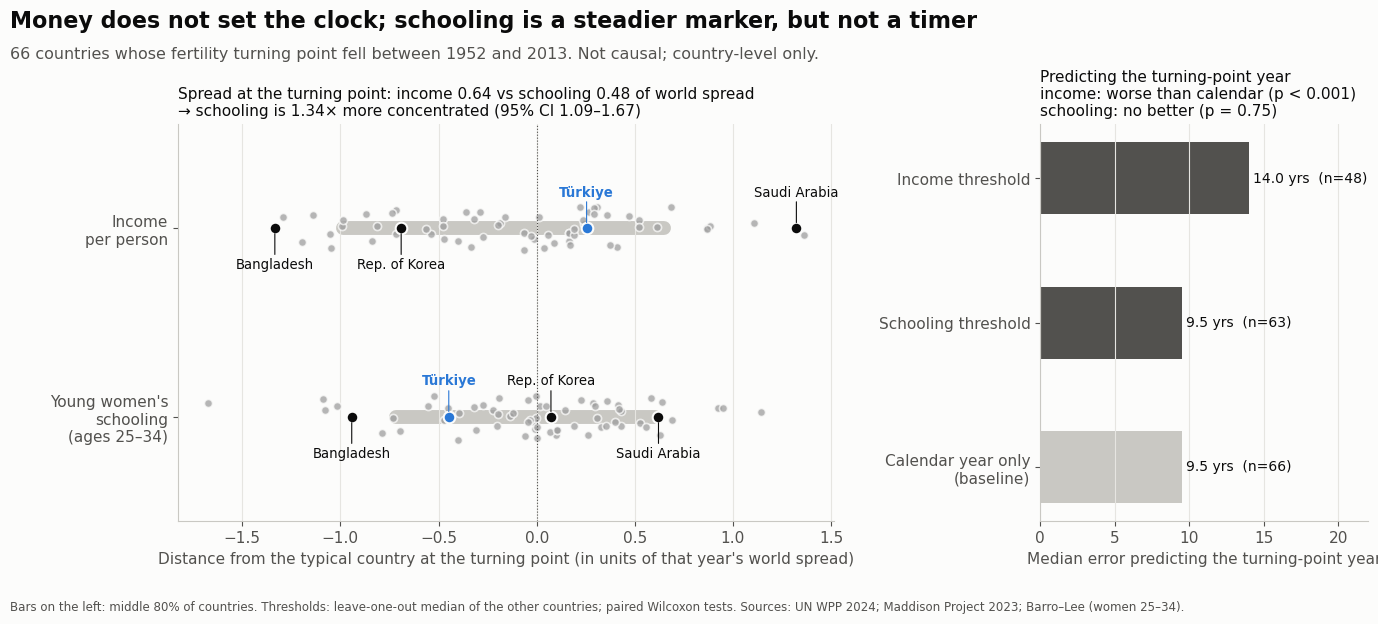

In [11]:
# 05'teki adil ölçeği yeniden üret: (log değer − medyan) / o yıl dünyadaki yayılım
def yillik(veri, kodlar):
    veri = veri[veri["ISO3_code"].isin(kodlar) & (veri["deger"] > 0)]
    s = {}
    for kod, d in veri.groupby("ISO3_code"):
        d = d.sort_values("year"); yy = np.arange(d["year"].min(), d["year"].max() + 1)
        s[kod] = pd.Series(np.interp(yy, d["year"], np.log(d["deger"])), index=yy)
    return pd.DataFrame(s).loc[1950:2015]
kodlar = t0["ISO3_code"]
G = yillik(pd.read_csv("../data_dis/gdp-per-capita-maddison-project-database.csv")
           .rename(columns={"code": "ISO3_code", "gdp_per_capita": "deger"}), kodlar)
E = yillik(pd.read_csv("../data_dis/barrolee_BL_v3_F2534.csv")
           .rename(columns={"WBcode": "ISO3_code", "yr_sch": "deger"}), kodlar)
po["yil"] = po["t0"].round().astype(int)
po["z_gelir"] = [(np.log(v) - np.log(po["gelir"]).median()) / G.loc[y].std() for v, y in zip(po["gelir"], po["yil"])]
po["z_egitim"] = [(np.log(v) - np.log(po["egitim"]).median()) / E.loc[y].std() for v, y in zip(po["egitim"], po["yil"])]

fig = plt.figure(figsize=(14, 6.2))
fig.subplots_adjust(top=0.80, bottom=0.16, left=0.13, right=0.98)
gs = fig.add_gridspec(1, 2, width_ratios=[2.0, 1], wspace=0.42)
a = fig.add_subplot(gs[0]); b = fig.add_subplot(gs[1])

# etiketli ülkeler: (görünen ad, etiket yönü eğitim satırında, gelir satırında); +1 üstte, −1 altta
etiket = {"Bangladesh": ("Bangladesh", -1, -1), "Türkiye": ("Türkiye", 1, 1),
          "Saudi Arabia": ("Saudi Arabia", -1, 1), "Republic of Korea": ("Rep. of Korea", 1, -1)}
rng = np.random.default_rng(3)
for satir, sutun in enumerate(["z_egitim", "z_gelir"]):
    yk = satir + rng.uniform(-0.12, 0.12, len(po))
    etiketli = po["Location"].isin(etiket)
    yk[etiketli.values] = satir                          # etiketli noktalar tam çizginin üstünde
    a.hlines(satir, po[sutun].quantile(0.1), po[sutun].quantile(0.9), color="#c9c8c3", lw=10, zorder=0, capstyle="round")
    a.scatter(po[sutun][~etiketli], yk[~etiketli.values], s=34, color=GRI, alpha=0.75, edgecolor="#fcfcfb", linewidth=1.2, zorder=2)
    for ulke, (ad, yon_e, yon_g) in etiket.items():
        j = np.where(po["Location"] == ulke)[0][0]
        r = MAVI if ulke == "Türkiye" else YAZI
        yon = yon_e if sutun == "z_egitim" else yon_g
        a.scatter(po[sutun].iloc[j], satir, s=70, color=r, edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
        a.annotate(ad, (po[sutun].iloc[j], satir), xytext=(0, 26 * yon), textcoords="offset points",
                   ha="center", va="center", fontsize=9.5, color=r, fontweight="bold" if ulke == "Türkiye" else None,
                   arrowprops=dict(arrowstyle="-", color=r, lw=0.8, shrinkA=0, shrinkB=4))
a.axvline(0, color=YAZI2, lw=0.8, ls=":")
a.set_yticks([0, 1], ["Young women's\nschooling\n(ages 25–34)", "Income\nper person"])
a.set_ylim(-0.55, 1.55); a.grid(axis="y", visible=False)
a.set_xlabel("Distance from the typical country at the turning point (in units of that year's world spread)")
a.set_title("Spread at the turning point: income 0.64 vs schooling 0.48 of world spread\n"
            "→ schooling is 1.34× more concentrated (95% CI 1.09–1.67)", loc="left", color=YAZI, fontsize=11)

hata = {"Income threshold": po["hata_gelir"].abs().median(),
        "Schooling threshold": po["hata_egitim"].abs().median(),
        "Calendar year only\n(baseline)": po["hata_takvim"].abs().median()}
nler = [po["hata_gelir"].notna().sum(), po["hata_egitim"].notna().sum(), po["hata_takvim"].notna().sum()]
yy = np.arange(3)[::-1]
b.barh(yy, list(hata.values()), height=0.5, color=[YAZI2, YAZI2, "#c9c8c3"])
for y_, v, nn in zip(yy, hata.values(), nler):
    b.text(v + 0.3, y_, f"{v:.1f} yrs  (n={nn})", va="center", fontsize=10, color=YAZI)
b.set_yticks(yy, list(hata.keys())); b.set_xlim(0, 22); b.grid(axis="y", visible=False)
b.set_xlabel("Median error predicting the turning-point year")
b.set_title("Predicting the turning-point year\nincome: worse than calendar (p < 0.001)\nschooling: no better (p = 0.75)",
            loc="left", color=YAZI, fontsize=11)
baslik(fig, "Money does not set the clock; schooling is a steadier marker, but not a timer",
       f"{len(po)} countries whose fertility turning point fell between 1952 and 2013. Not causal; country-level only.")
kaynak(fig, "Bars on the left: middle 80% of countries. Thresholds: leave-one-out median of the other countries; paired Wilcoxon tests. "
             "Sources: UN WPP 2024; Maddison Project 2023; Barro–Lee (women 25–34).")
plt.savefig("../outputs/final_2_money_or_school.png", dpi=150); plt.show()

## Grafik 3: Türkiye

Sol: Türkiye nüfusu, UN'in %80 ve %95 tahmin aralıklarıyla (OtherVariants dosyası). Sağ: Türkiye dönüm noktasında (1982) 66 ülke arasında nerede?

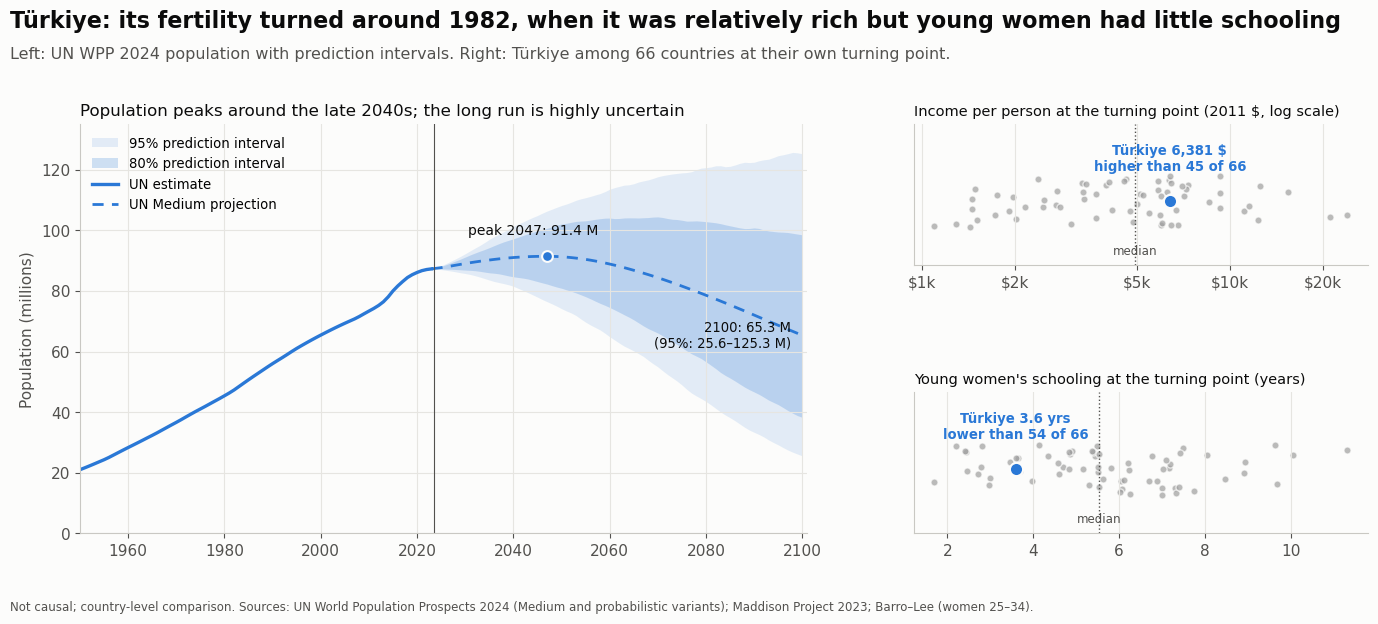

In [12]:
ov = pd.read_csv("../data/WPP2024_Demographic_Indicators_OtherVariants_csv.gz", encoding="utf-8-sig",
                 usecols=["LocID", "Variant", "Time", "TPopulation1July"])
ov = ov[(ov["LocID"] == 792) & ov["Variant"].str.contains("PI") & (ov["Time"] <= 2100)]
pi = ov.pivot(index="Time", columns="Variant", values="TPopulation1July") / 1000      # milyon
trp = df[df["Location"] == "Türkiye"].set_index("Time")["TPopulation1July"] / 1000
zirve = trp.idxmax()

fig = plt.figure(figsize=(14, 6.2))
fig.subplots_adjust(top=0.80, bottom=0.14, left=0.06, right=0.98)
gs = fig.add_gridspec(2, 2, width_ratios=[1.6, 1], hspace=0.9, wspace=0.18)
a = fig.add_subplot(gs[:, 0])
a.fill_between(pi.index, pi["Lower 95 PI"], pi["Upper 95 PI"], color=MAVI, alpha=0.12, lw=0, label="95% prediction interval")
a.fill_between(pi.index, pi["Lower 80 PI"], pi["Upper 80 PI"], color=MAVI, alpha=0.22, lw=0, label="80% prediction interval")
a.plot(trp.loc[:2023], color=MAVI, lw=2.4, label="UN estimate")
a.plot(trp.loc[2023:], color=MAVI, lw=2, ls=(0, (4, 3)), label="UN Medium projection")
a.axvline(2023.5, color=YAZI2, lw=0.8)
a.scatter([zirve], [trp[zirve]], s=60, color=MAVI, edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
a.annotate(f"peak {zirve}: {trp[zirve]:.1f} M", (zirve, trp[zirve]), xytext=(-10, 16), textcoords="offset points",
           ha="center", fontsize=10, color=YAZI)
son = 2100
a.annotate(f"2100: {trp[son]:.1f} M\n(95%: {pi.at[son, 'Lower 95 PI']:.1f}–{pi.at[son, 'Upper 95 PI']:.1f} M)",
           (son, trp[son]), xytext=(-8, 0), textcoords="offset points", ha="right", va="center", fontsize=9.5, color=YAZI)
a.set_ylabel("Population (millions)"); a.set_ylim(0, 135); a.set_xlim(1950, 2101)
a.legend(frameon=False, loc="upper left", fontsize=9.5)
a.set_title("Population peaks around the late 2040s; the long run is highly uncertain", loc="left", color=YAZI)

tr = po[po["Location"] == "Türkiye"].iloc[0]
for satir, (sutun, ad, bicim) in enumerate([("gelir", "Income per person at the turning point (2011 $, log scale)", "{:,.0f} $"),
                                            ("egitim", "Young women's schooling at the turning point (years)", "{:.1f} yrs")]):
    b = fig.add_subplot(gs[satir, 1])
    b.scatter(po[sutun], np.random.default_rng(satir).uniform(-0.3, 0.3, len(po)), s=26, color=GRI, alpha=0.7,
              edgecolor="#fcfcfb", linewidth=1)
    b.axvline(po[sutun].median(), color=YAZI2, lw=1, ls=":")
    b.scatter([tr[sutun]], [0], s=90, color=MAVI, edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
    alti = (po[sutun] < tr[sutun]).sum(); ustu = (po[sutun] > tr[sutun]).sum()
    konum = f"higher than {alti} of {len(po)}" if sutun == "gelir" else f"lower than {ustu} of {len(po)}"
    b.annotate(f"Türkiye {bicim.format(tr[sutun])}\n{konum}", (tr[sutun], 0), xytext=(0, 22),
               textcoords="offset points", ha="center", fontsize=9.5, color=MAVI, fontweight="bold")
    b.text(po[sutun].median(), -0.62, "median", ha="center", fontsize=8.5, color=YAZI2)
    if sutun == "gelir":
        b.set_xscale("log")
        b.set_xticks([1000, 2000, 5000, 10000, 20000], ["$1k", "$2k", "$5k", "$10k", "$20k"])
        b.minorticks_off()
    b.set_yticks([]); b.set_ylim(-0.75, 0.9); b.grid(axis="y", visible=False)
    b.set_title(ad, loc="left", color=YAZI, fontsize=10.5)
baslik(fig, "Türkiye: its fertility turned around 1982, when it was relatively rich but young women had little schooling",
       "Left: UN WPP 2024 population with prediction intervals. Right: Türkiye among 66 countries at their own turning point.")
kaynak(fig, "Not causal; country-level comparison. Sources: UN World Population Prospects 2024 (Medium and probabilistic variants); "
             "Maddison Project 2023; Barro–Lee (women 25–34).")
plt.savefig("../outputs/final_3_turkiye.png", dpi=150); plt.show()